# Ashaar_meter: Exploratory Data Analysis
**Dataset:** [`arbml/Ashaar_meter`](https://huggingface.co/datasets/arbml/Ashaar_meter) · 

**Goal.** Understand the dataset (Arabic verses, each labeled with its بحر) before building a meter classifier, and list the problems the team has to handle.

**How to run.** Put the dataset in `../data/Ashaar_meter/` (`train-00000-of-00001.parquet` and `test-00000-of-00001.parquet`) and run the notebook top to bottom.

**Contents**
1. Loading and first look
2. Columns: types, nulls, labels
3. Duplicates and conflicting labels
4. Bad rows (empty halves, extra `#`)
5. Train/test leakage
6. Characters and التشكيل
7. Verse length and outliers
8. Visualizations
9. Bottlenecks and purpose of the dataset
10. Preprocessing and feature engineering
11. ydata_profiling report
12. Model recommendation

In [1]:
import os, re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 200)

# Arabic letters (ء to غ, ف to ي, plus ٱ) and التشكيل (ً ٌ ٍ َ ُ ِ ّ ْ)
LETTERS = r"[\u0621-\u063A\u0641-\u064A\u0671]"
DIACRITICS = r"[\u064B-\u0652]"

## 1. Loading and first look

In [2]:
train_df = pd.read_parquet("../data/Ashaar_meter/train-00000-of-00001.parquet")
test_df = pd.read_parquet("../data/Ashaar_meter/test-00000-of-00001.parquet")

In [3]:
print(train_df.shape, test_df.shape)

(1449171, 2) (362798, 2)


In [4]:
train_df.sample(n=5, random_state=42)

,text,label
1084691,فَمَنْ يَكُ بِالْبِيضِ الْكوَاعِبِ مُغْرماً # ...,taweel
1189774,تَناهَبَتِ العَيشَ النُفوسُ بِغِرَّةٍ # فَإِن ...,taweel
454907,بنات قوم وأَزوا # ج آخرين استقلوا,mujtath
1412461,وبغناك المطلق المجرد # بلطفك الخافي بفيض المدد,rajaz
929022,نَدِمْتُ على شَتْمِ العشيرةِ بعدَما # مضَى واس...,taweel


In [5]:
test_df.head()

,text,label
0,أنظر لقولي منصفا مفكراً # حينا وعوّق بعد أو أطلقِ,saree
1,أَيُّ مَيْتٍ مِثْلي وَلَسْتَ تَرَاهُ # عادَهُ ...,khafeef
2,يا أمة الوادي تحية مخلص # بحياته للمخلصين جواد,kamel
3,فثملت من اسكارها ولثمت من # ابكارها وشممت من ا...,kamel
4,وَكَأَنَّما أُخفي عَليكَ بِصَحّتي # سَقَماً فَ...,kamel


**Findings**
- Train has **1,449,171** rows and test **362,798**, with **2 columns** each (`text`, `label`). Together that is 1,811,969 rows, which matches the dataset page.
- Each `text` is a full بيت: the two أشطر (الصدر والعجز) separated by `#`.
- **Train is sorted by label** (the first rows are all `saree`), while test looks shuffled.
- The التشكيل is **mixed**: some verses are marked, some are not (see section 6).

## 2. Columns: types, nulls, labels
The data types and missing values decide how each column is processed, and the label counts show the class balance.
**Action:** `info()`, null counts and percentages, number of unique labels, and the count of each label in train and test.

In [6]:
train_df.info()
print("ــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــ")
test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1449171 entries, 0 to 1449170
Data columns (total 2 columns):
 #   Column  Non-Null Count    Dtype 
---  ------  --------------    ----- 
 0   text    1449171 non-null  object
 1   label   1449171 non-null  object
dtypes: object(2)
memory usage: 22.1+ MB
ــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــ
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 362798 entries, 0 to 362797
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   text    362798 non-null  object
 1   label   362798 non-null  object
dtypes: object(2)
memory usage: 5.5+ MB


In [7]:
nullSummary_train = pd.DataFrame({
    'null_count': train_df.isnull().sum(),
    'null_pct': (train_df.isnull().mean() * 100).round(2)
})

print(nullSummary_train)

print("ــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــ")


nullSummary_test = pd.DataFrame({
    'null_count': test_df.isnull().sum(),
    'null_pct': (test_df.isnull().mean() * 100).round(2)
})

print(nullSummary_test)


       null_count  null_pct
text            0       0.0
label           0       0.0
ــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــ
       null_count  null_pct
text            0       0.0
label           0       0.0


In [8]:
# Number of unique labels
num_unique_train = train_df['label'].nunique()
print(f"Unique train labels: {num_unique_train}\n")

num_unique_test = test_df['label'].nunique()
print(f"Unique test labels: {num_unique_test}\n")

Unique train labels: 17

Unique test labels: 17



In [9]:
# Count of each label (sorted descending)
print("Train label count")
print(train_df['label'].value_counts())

print("ــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــ")

print("Test label count")
print(test_df['label'].value_counts())

Train label count
label
taweel       336923
kamel        308754
baseet       201368
khafeef      131744
wafer        113315
rajaz         98056
ramal         66529
mutakareb     55166
saree         49487
prose         25624
munsareh      23324
mujtath       14863
mutadarak     10578
hazaj          6531
madeed         6154
muqtadheb       644
mudhare         111
Name: count, dtype: int64
ــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــ
Test label count
label
taweel       85470
kamel        77981
baseet       50877
khafeef      33435
wafer        28709
rajaz        24895
ramal        16735
mutakareb    13960
saree        12418
munsareh      5912
mujtath       3736
mutadarak     2657
prose         2635
hazaj         1649
madeed        1539
muqtadheb      162
mudhare         28
Name: count, dtype: int64


**Findings**
| Column | Type | Nulls |
|---|---|---|
| `text` | string (`object`) | 0 (0.0%) |
| `label` | string (`object`) | 0 (0.0%) |

- The 17 labels are the **16 بحور** plus **`prose`**, which is not a meter.
- **Strong class imbalance.** `taweel` (الطويل) has 336,923 verses (23.2% of train), `kamel` (الكامل) 308,754 and `baseet` (البسيط) 201,368, so the top 3 make up about **58%**. The smallest classes are `muqtadheb` (المقتضب) with 644 and `mudhare` (المضارع) with **111**. The ratio between largest and smallest is about **3,000 to 1**.
- Train and test class proportions match closely, **except `prose`**: 1.77% of train (25,624) but 0.73% of test (2,635). Test also has only 28 `mudhare` and 162 `muqtadheb` rows.
- **Proposed action:** encode labels as integers and save the mapping; use class weights and macro-F1; should `prose` stay?

## 3. Duplicates and conflicting labels
repeated verses make a model memorize and inflate scores, and one verse with two labels teaches contradictions.
**Action:** count repeated texts, exact duplicate rows (text and label), and texts that have more than one label. Repeat for test.

In [10]:
train_df["text"].duplicated().sum()

np.int64(514)

In [11]:
test_df["text"].duplicated().sum()

np.int64(1169)

In [12]:
train_df.duplicated(subset=["text", "label"]).sum()

np.int64(0)

In [13]:
test_df.duplicated(subset=["text", "label"]).sum()

np.int64(1146)

In [14]:
# Count unique labels per distinct text
label_counts_train = train_df.groupby("text")["label"].nunique()
label_counts_test = test_df.groupby("text")["label"].nunique()

# Filter for texts with conflicting labels (> 1)
conflicting_texts_train = label_counts_train[label_counts_train > 1]
conflicting_texts_test = label_counts_test[label_counts_test > 1]

# Total number of distinct texts with multiple labels
print("Count train:", len(conflicting_texts_train))
print("Count test:", len(conflicting_texts_test))

Count train: 510
Count test: 23


In [15]:
# Grab up to 5 conflicting text values and inspect their rows in the original DataFrame
sample_texts_train = conflicting_texts_train.index[:5]
train_df[train_df["text"].isin(sample_texts_train)].sort_values("text")

,text,label
227422,#,kamel
375211,#,mutakareb
415830,#,mutadarak
488626,#,ramal
756458,#,khafeef
1222209,#,wafer
169864,أباحك حسن الذكر والأجر منهم # ومن ربهم عدل أتي...,kamel
933456,أباحك حسن الذكر والأجر منهم # ومن ربهم عدل أتي...,taweel
627195,أبي اللَه أن ترضى بأني طالِبٌ # رضاكَ وأني بعد...,baseet
944893,أبي اللَه أن ترضى بأني طالِبٌ # رضاكَ وأني بعد...,taweel


In [16]:
sample_texts_test = conflicting_texts_test.index[:5]
test_df[test_df["text"].isin(sample_texts_test)].sort_values("text")

,text,label
38787,#,khafeef
282646,#,baseet
310268,إنْ تَسْرِ كان لك النَّجاحُ مُصاحباً # أو تَبْ...,taweel
315257,إنْ تَسْرِ كان لك النَّجاحُ مُصاحباً # أو تَبْ...,kamel
79537,إِذا الغَمامَةُ لاحَتْ خاضَ ساكِنُها # حِياضَه...,saree
147516,إِذا الغَمامَةُ لاحَتْ خاضَ ساكِنُها # حِياضَه...,baseet
12888,إِذا ما اِحتَبَت لي دارِمٌ عِندَ غايَةٍ # جَرَ...,taweel
31583,إِذا ما اِحتَبَت لي دارِمٌ عِندَ غايَةٍ # جَرَ...,baseet
91329,الباذِلَين لَدَى الفِدَاءِ نُفوسَهُمْ # يَبغون...,ramal
323898,الباذِلَين لَدَى الفِدَاءِ نُفوسَهُمْ # يَبغون...,kamel


**Findings**
| | Train | Test |
|---|---|---|
| Rows with a repeated `text` | 514 | 1,169 |
| Exact duplicate rows (`text` + `label`) | **0** | **1,146** |
| Distinct texts with more than one label | 510 | 23 |

- In train every repeated text carries different labels, so train looks already deduplicated on `text` + `label`. **Test was not.** The two files were cleaned differently.
- One of the 510 train conflicts is the text `#` (an empty verse, see section 4), so about **509 are real verses** with conflicting labels. Examples: the same verse labeled both `kamel` and `taweel`.
- This is label noise: the cause (annotation errors, or a verse that really fits two meters) is unknown.
- **Proposed action:** drop all copies of conflicting verses (about 0.035% of train), and drop exact duplicates from test.

## 4. Bad rows (empty halves, extra `#`)
A verse should have exactly two non-empty أشطر. Rows that don't are not valid input for a meter classifier.
**Action:** find rows that are only `#` or have no Arabic letters, rows without exactly one `#`, and rows where one side of the `#` is empty.

In [17]:
for name, df in [("Train", train_df), ("Test", test_df)]:
    s = df["text"].astype(str)

    is_only_hash = s.str.strip() == "#"
    has_no_arabic = ~s.str.contains(r"[\u0600-\u06FF]", regex=True)
    
    only_hash = (s.str.strip() == "#").sum()
    no_arabic = (~s.str.contains(r"[\u0600-\u06FF]", regex=True)).sum()
    either_condition = (is_only_hash | has_no_arabic).sum()
    
    print(f"{name} - Exactly '#': {only_hash} | No Arabic: {no_arabic} | Combined (either): {either_condition}")

Train - Exactly '#': 6 | No Arabic: 6 | Combined (either): 6
Test - Exactly '#': 2 | No Arabic: 2 | Combined (either): 2


In [18]:
for name, df in [("Train", train_df), ("Test", test_df)]:
    hash_counts = df["text"].astype(str).str.count("#")
    
    no_hash = (hash_counts == 0).sum()
    multi_hash = (hash_counts > 1).sum()
    
    print(f"{name} - No '#': {no_hash} | More than one '#': {multi_hash}")

Train - No '#': 0 | More than one '#': 25
Test - No '#': 0 | More than one '#': 6


In [19]:
multi_hash_rows_train = train_df[train_df["text"].astype(str).str.count("#") > 1]

with pd.option_context("display.max_colwidth", None, "display.max_rows", 30):
    print(multi_hash_rows_train[["text", "label"]])

                                                text   label
875792                 فسلي ثيابي من ثيابك تنسلِ # #  taweel
880093            وليسَ فؤادي عن هواها بِمُنسَلِ # #  taweel
881370    كَجُلمُودِ صخرٍ حَطَّهُ السيلُ من عَلِ # #  taweel
883895              قفا نبك من ذكرى حبيبٍ ومنزلِ # #  taweel
890380            نصيحٍ على تعذالِهِ غيرِ مُؤتلِ # #  taweel
920609                فألهيتها عن ذي تمائم محولِ # #  taweel
928329            بسقء اللوى بين الدخولِ فحومَلِ # #  taweel
942473      فأنزلَ منهُ العُصمَ من كُلِّ مَنزِلِ # #  taweel
960318                 منارةُ ممسى راهِبٍ متبتلِ # #  taweel
985753   نُزولَ اليَماني ذي العِيابِ المُحَمَّلِ # #  taweel
994440           بسهميكَ في أعشارِ قلبٍ مُقتَّلِ # #  taweel
996739        عُصارةَ حَنَّاءٍ بِشَيبٍ مُرَجَّلِ # #  taweel
1011777           وأنكِ مهما تأمري القلبَ يَفعلِ # #  taweel
1013788        بجيدِ مُعَمٍّ في العشيرةِ مُخوَلِ # #  taweel
1017617               يقولونَ لا تهلك أسى وتجملِ # #  taweel
1030802               بش

In [20]:
def shape(t):
    parts = [p.strip() for p in t.split("#")]
    return tuple(bool(p) for p in parts)   # True = has words, False = empty

multi_train = train_df[train_df["text"].astype(str).str.count("#") > 1]
multi_test = test_df[test_df["text"].astype(str).str.count("#") > 1]

print(multi_train["text"].astype(str).map(shape).value_counts())
print(multi_test["text"].astype(str).map(shape).value_counts())

text
(True, False, False)    25
Name: count, dtype: int64
text
(True, False, False)    6
Name: count, dtype: int64


In [21]:
print(multi_train["label"].value_counts())
print(multi_test["label"].value_counts())

label
taweel    25
Name: count, dtype: int64
label
taweel    6
Name: count, dtype: int64


In [22]:
for name, df in [("Train", train_df), ("Test", test_df)]:
    # Split into two halves on the first '#'
    halves = df["text"].astype(str).str.split("#", n=1, expand=True)
    
    left_empty = halves[0].str.strip() == ""
    # If there was no '#' at all, halves[1] is None/NaN; treat missing or whitespace-only as empty
    right_empty = halves[1].isna() | (halves[1].str.strip() == "")
    
    half_verse_mask = left_empty | right_empty
    half_verses = df[half_verse_mask].copy()
    half_verses["char_len"] = half_verses["text"].astype(str).str.len()
    
    print(f"=== {name} ===")
    print(f"Total half-verse / missing-side rows: {len(half_verses)} ({len(half_verses)/len(df):.2%})")
    print(f"  Left side empty  ('# ...'): {left_empty.sum()}")
    print(f"  Right side empty ('... #'): {right_empty.sum()}")
    
    print("\nLabel distribution:")
    print(half_verses["label"].value_counts())
    
    print("\nCharacter length stats:")
    print(half_verses["char_len"].describe().round(2))
    
    with pd.option_context("display.max_colwidth", None):
        print("\nSample rows:")
        print(half_verses[["char_len", "label", "text"]].head(10))
    print("\n" + "="*40 + "\n")

=== Train ===
Total half-verse / missing-side rows: 6291 (0.43%)
  Left side empty  ('# ...'): 408
  Right side empty ('... #'): 5889

Label distribution:
label
kamel        1245
ramal        1214
khafeef       956
rajaz         884
mutakareb     545
baseet        458
taweel        364
saree         169
mutadarak     169
wafer         146
mujtath        58
hazaj          44
madeed         25
munsareh       10
prose           4
Name: count, dtype: int64

Character length stats:
count    6291.00
mean       26.32
std         7.68
min         1.00
25%        23.00
50%        26.00
75%        29.00
max        78.00
Name: char_len, dtype: float64

Sample rows:
      char_len  label                          text
44          24  saree      عبر صحاري الظمأ الملهب #
70          26  saree    فاملأ لنا في كل يوم وعاء #
134         28  saree  ينضحن من حيث التقى بالصخور #
869         27  saree   يا توأم الروح و نور البصر #
1480        17  saree             أصداؤها الحمراء #
1805        19  saree    

In [23]:
for name, df in [("Train", train_df), ("Test", test_df)]:
    s = df["text"].astype(str)
    halves = s.str.split("#", n=1, expand=True)
    
    bad_hash_count = s.str.count("#") != 1
    no_arabic = ~s.str.contains(r"[\u0600-\u06FF]", regex=True)
    empty_half = (halves[0].str.strip() == "") | (halves[1].isna()) | (halves[1].str.strip() == "")
    
    drop_mask = bad_hash_count | no_arabic | empty_half
    
    print(f"{name} - Bad '#' count (!=1): {bad_hash_count.sum()} | No Arabic: {no_arabic.sum()} | Empty half: {empty_half.sum()}")
    print(f"{name} - Total unique rows to drop so far: {drop_mask.sum()} / {len(df)}\n")

Train - Bad '#' count (!=1): 25 | No Arabic: 6 | Empty half: 6291
Train - Total unique rows to drop so far: 6316 / 1449171

Test - Bad '#' count (!=1): 6 | No Arabic: 2 | Empty half: 1531
Test - Total unique rows to drop so far: 1537 / 362798



**Findings**
| Check | Train | Test |
|---|---|---|
| Text is only `#` (no Arabic) | 6 | 2 |
| No `#` at all | 0 | 0 |
| More than one `#` | 25 | 6 |
| One half empty (`# …` or `… #`) | 6,291 (408 left empty, 5,889 right empty) | 1,531 (111 left, 1,422 right) |
| **Total rows to drop** | **6,316 (0.44%)** | **1,537 (0.42%)** |

- The 25 train and 6 test rows with two `#` all look like `first half # #`, with the second half missing. **All of them are labeled `taweel`**, which could become a false shortcut for a model.
- Half verses are about 26 characters on average (half the normal length).
- The share is the same in both files (0.43% and 0.42%), so it is a systematic property of the data.
- The problem is not even across meters: about **1.8%** of `ramal` and **1.6%** of `mutadarak` rows are half verses, against about **0.1%** of `taweel`.
- **Proposed action:** drop these rows.

## 5. Train/test leakage
If a verse is in both files, the model is tested on something it has already seen, so the test score looks better than it is.
**Action:** strip whitespace, then count the train rows whose text also appears in test, and check whether the labels agree.

In [24]:
# Normalize whitespace first so minor trailing spaces don't hide leaks
train_clean = train_df["text"].astype(str).str.strip()
test_clean = test_df["text"].astype(str).str.strip()

# 1. Number of rows in train whose verse also exists in test
leaked_train_rows = train_clean.isin(set(test_clean)).sum()

# 2. Number of unique verses shared between train and test
shared_unique_verses = len(set(train_clean) & set(test_clean))

print(f"Train rows appearing in test: {leaked_train_rows}")
print(f"Unique overlapping verses: {shared_unique_verses}")

Train rows appearing in test: 8944
Unique overlapping verses: 8935


In [25]:
leaked_examples = list(set(train_clean) & set(test_clean))[:5]
train_df[train_clean.isin(leaked_examples)]

,text,label
346468,والمنقذ الإسلام حين تمزقت # أشلاؤه بشباة ناب أعصل,kamel
747570,ارقصوا رقصة الحياة أو المو # ت إذا مات سيد أو ...,khafeef
991018,وقد كان يستحبي الزمانُ خِلالها # حَياً منهمُ غ...,taweel
1045074,فَلا وَالَّذي مَسَّحتُ أَركانَ بَيتِهِ # أَطوف...,taweel
1050929,وصيروا جميعاً عالمينَ وعلّموا # بنيكم بترغيبٍ ...,taweel


In [26]:
# Clean whitespace so matching matches your leakage check
train_clean = train_df.assign(text_clean=train_df["text"].astype(str).str.strip())
test_clean = test_df.assign(text_clean=test_df["text"].astype(str).str.strip())

# Map each distinct verse to the set of labels it has in train vs. test
train_labels = train_clean.groupby("text_clean")["label"].apply(set)
test_labels = test_clean.groupby("text_clean")["label"].apply(set)

# Combine into one DataFrame keeping only verses present in BOTH splits
shared = pd.DataFrame({"train_labels": train_labels, "test_labels": test_labels}).dropna()

# Check exact agreement (both have a single identical label) vs. any disagreement
exact_match = shared.apply(
    lambda r: len(r["train_labels"]) == 1 and r["train_labels"] == r["test_labels"], 
    axis=1
)

print(f"Total shared unique verses: {len(shared)}")
print(f"Exact label agreement:      {exact_match.sum()} ({exact_match.mean():.1%})")
print(f"Disagreement / ambiguous:   {(~exact_match).sum()} ({(~exact_match).mean():.1%})")

Total shared unique verses: 8935
Exact label agreement:      8631 (96.6%)
Disagreement / ambiguous:   304 (3.4%)


In [27]:
with pd.option_context("display.max_colwidth", None):
    print(shared[~exact_match].head(10))

                                                                                                          train_labels  \
text_clean                                                                                                               
#                                                                 {mutadarak, ramal, mutakareb, wafer, kamel, khafeef}   
آباؤُكَ الأشرافُ إلا أنهم # أشرافُ موشَ وشاطحٍ وخِلاطِ                                                        {baseet}   
آنستُ منها بخَيالٍ آنسٍ # يُسابِقُ الغُمْضَ إذا الغُمْضُ ألَمّ                                              {munsareh}   
أأقومُ بين يَدَي سواه مؤمِّلاً # وأُنيخُ راحلةَ الرَّجاءِ ببابِه                                               {kamel}   
أأهنأُ بالدنيا ومولاي واجِدٌ # على وأرضاها ومولاى مغضَبُ                                                      {taweel}   
أبكي فيبكي كأنَّا # حمائمُ النوحِ بعدَك                                                                      {mujtath}   
أتنكر حقَّ قدّيسٍ طهورٍ 

**Findings**
- **8,935 distinct verses** (8,944 train rows) appear in both train and test.
- For those shared verses, **8,631 (96.6%)** have the same label in both files, and **304 (3.4%)** do not. More evidence of label noise. The disagreements include the `#` text.
- This check only finds **exact** matches. The same verse with different التشكيل would not be detected, so the real leakage is probably higher. Repeat the check after the text is normalized.
- **Proposed action:** remove the shared verses from **train**, and leave test untouched.

## 6. Characters and التشكيل
A model should only see characters that matter for rhythm, and the بحر depends on the حركات, so we need to know how much تشكيل the data has.
**Action** list every distinct character and flag the unexpected ones; check for التطويل (ـ), digits and Latin letters; compute the ratio of التشكيل marks to letters per verse; compare the ratio across labels.

In [28]:
# Count all characters in train_df["text"] (or pd.concat([train_df["text"], test_df["text"]]))
char_counts = Counter("".join(train_df["text"].astype(str)))

print(f"Total distinct characters: {len(char_counts)}")
print("Most common:", char_counts.most_common(15))

# Filter for characters that are NOT:
# - Arabic letters (\u0621-\u064A, \u0671)  [Note: \u0640 is tatweel, included in range unless excluded]
# - Diacritics (\u064B-\u0652, \u0670)
# - Space (" ") or "#"
allowed_pattern = re.compile(r"^[\u0621-\u063A\u0641-\u064A\u0671\u064B-\u0652\u0670 #]$")

unwanted_chars = {
    ch: count for ch, count in char_counts.items() 
    if not allowed_pattern.match(ch)
}

# Sort unwanted characters by frequency descending
for ch, count in sorted(unwanted_chars.items(), key=lambda x: -x[1]):
    print(f"{repr(ch):6s} (U+{ord(ch):04X}): {count}")

Total distinct characters: 47
Most common: [(' ', 13557768), ('ا', 7943911), ('َ', 6436311), ('ل', 6025648), ('م', 3762528), ('ي', 3676631), ('ن', 3270775), ('و', 3269400), ('ِ', 2968152), ('ر', 2566925), ('ُ', 2473968), ('ب', 2353134), ('ه', 2256209), ('ت', 2106675), ('ع', 1912423)]
'ٓ'    (U+0653): 1


In [29]:
for name, df in [("Train", train_df), ("Test", test_df)]:
    has_diacritics = df["text"].astype(str).str.contains(r"[\u064B-\u0652]", regex=True)
    
    with_pct = has_diacritics.mean() * 100
    without_pct = (~has_diacritics).mean() * 100
    
    print(f"{name} - With diacritics: {with_pct:.2f}% ({has_diacritics.sum()}) | No diacritics: {without_pct:.2f}% ({(~has_diacritics).sum()})")

Train - With diacritics: 80.41% (1165225) | No diacritics: 19.59% (283946)
Test - With diacritics: 80.60% (292398) | No diacritics: 19.40% (70400)


In [30]:
for name, df in [("Train", train_df), ("Test", test_df)]:
    s = df["text"].astype(str)
    
    has_tatweel = s.str.contains("\u0640", regex=False).sum()
    has_digits  = s.str.contains(r"[0-9\u0660-\u0669\u06F0-\u06F9]", regex=True).sum()
    has_latin   = s.str.contains(r"[A-Za-z]", regex=True).sum()
    
    print(f"{name} - Tatweel: {has_tatweel} | Digits: {has_digits} | Latin letters: {has_latin}")

Train - Tatweel: 0 | Digits: 0 | Latin letters: 0
Test - Tatweel: 0 | Digits: 0 | Latin letters: 0


In [31]:
s = train_df["text"].astype(str)

n_diacritics = s.str.count(r"[\u064B-\u0652]")
n_letters = s.str.count(r"[\u0621-\u063A\u0641-\u064A\u0671]")

# Avoid division by zero for rows with no Arabic letters
train_df["diac_ratio"] = n_diacritics / n_letters.replace(0, float("nan"))

print(train_df["diac_ratio"].describe())

# Categorize into None, Partial, and Near Full
buckets = pd.cut(
    train_df["diac_ratio"],
    bins=[-1, 0, 0.5, float("inf")],
    labels=["None (0)", "In between (0 - 0.5)", "Near full (>= 0.5)"]
)
print("\nDistribution:")
print(buckets.value_counts().to_frame("count").assign(pct=lambda d: (d["count"] / len(train_df) * 100).round(2)))

count    1.449165e+06
mean     2.721891e-01
std      2.437048e-01
min      0.000000e+00
25%      2.777778e-02
50%      2.307692e-01
75%      4.750000e-01
max      1.235294e+00
Name: diac_ratio, dtype: float64

Distribution:
                       count    pct
diac_ratio                         
In between (0 - 0.5)  861814  59.47
Near full (>= 0.5)    303411  20.94
None (0)              283940  19.59


In [32]:
label_diac_stats = (
    train_df.assign(is_undiacritized=train_df["diac_ratio"] == 0)
    .groupby("label")
    .agg(
        total_verses=("text", "count"),
        mean_diac_ratio=("diac_ratio", "mean"),
        pct_undiacritized=("is_undiacritized", lambda x: x.mean() * 100),
        pct_heavily_diacritized=("diac_ratio", lambda x: (x >= 0.5).mean() * 100),
    )
    .sort_values("pct_undiacritized", ascending=False)
)

print(label_diac_stats.round(2))

           total_verses  mean_diac_ratio  pct_undiacritized  \
label                                                         
prose             25624             0.56              29.95   
mujtath           14863             0.23              26.96   
ramal             66529             0.22              23.62   
rajaz             98056             0.26              22.57   
mudhare             111             0.26              22.52   
muqtadheb           644             0.32              21.74   
khafeef          131744             0.24              21.56   
saree             49487             0.26              20.08   
kamel            308754             0.27              20.04   
madeed             6154             0.29              19.65   
baseet           201368             0.26              19.31   
wafer            113315             0.27              18.10   
hazaj              6531             0.28              17.50   
taweel           336923             0.29              1

In [33]:
s_test = test_df["text"].astype(str)

n_diacritics = s_test.str.count(r"[\u064B-\u0652]")
n_letters = s_test.str.count(r"[\u0621-\u063A\u0641-\u064A\u0671]")

test_df["diac_ratio"] = n_diacritics / n_letters.replace(0, float("nan"))

print(test_df["diac_ratio"].describe())

buckets = pd.cut(
    test_df["diac_ratio"],
    bins=[-1, 0, 0.5, float("inf")],
    labels=["None (0)", "In between (0 - 0.5)", "Near full (>= 0.5)"]
)
print("\nDistribution:")
print(buckets.value_counts().to_frame("count").assign(pct=lambda d: (d["count"] / len(test_df) * 100).round(2)))

count    362796.000000
mean          0.269529
std           0.239050
min           0.000000
25%           0.027778
50%           0.230769
75%           0.472222
max           1.214286
Name: diac_ratio, dtype: float64

Distribution:
                       count    pct
diac_ratio                         
In between (0 - 0.5)  218336  60.18
Near full (>= 0.5)     74062  20.41
None (0)               70398  19.40


In [34]:
test_label_diac_stats = (
    test_df.assign(is_undiacritized=test_df["diac_ratio"] == 0)
    .groupby("label")
    .agg(
        total_verses=("text", "count"),
        mean_diac_ratio=("diac_ratio", "mean"),
        pct_undiacritized=("is_undiacritized", lambda x: x.mean() * 100),
        pct_heavily_diacritized=("diac_ratio", lambda x: (x >= 0.5).mean() * 100),
    )
    .sort_values("pct_undiacritized", ascending=False)
)

print(test_label_diac_stats.round(2))

           total_verses  mean_diac_ratio  pct_undiacritized  \
label                                                         
mudhare              28             0.21              35.71   
prose              2635             0.50              29.87   
mujtath            3736             0.23              29.01   
muqtadheb           162             0.32              25.93   
ramal             16735             0.21              24.17   
rajaz             24895             0.26              22.07   
khafeef           33435             0.24              21.65   
madeed             1539             0.28              20.79   
saree             12418             0.26              20.66   
kamel             77981             0.27              19.89   
baseet            50877             0.26              18.84   
wafer             28709             0.27              18.46   
taweel            85470             0.29              17.20   
mutakareb         13960             0.28              1

**Findings**
- Train has only **47 distinct characters**. The only unexpected one is `ٓ` (المدّة, `U+0653`), **once**. There is **no** تطويل, **no** digits and **no** Latin letters in either file. Apart from the `#`, the text is clean.
- **80.4%** of train verses contain at least one تشكيل mark (80.6% of test). But "has a mark" is not "fully marked".
- Using the ratio of marks to letters, in train: **19.6%** have none, **59.5%** have a few (ratio below 0.5), **20.9%** have 0.5 or more. Test: 19.4%, 60.2%, 20.4%. The ratio can exceed 1, because a letter can carry two marks (for example شدّة and فتحة).
- The histogram shows a second hump near 0.5, which is probably the fully marked verses. The 0.5 cut-off splits that hump, so **the 20.9% is likely an underestimate**. *(To verify by reading verses in that range.)*
- **By label:** most meters have a similar share of unmarked verses (about 17 to 24%). **`prose` stands out**: mean ratio 0.56 (the meters are 0.22 to 0.32) and 67% heavily marked (the meters 6 to 33%). `mutadarak` (المتدارك) has the fewest unmarked verses (about 10%).
- **Consequence:** most verses are only partly مشكولة, so a تشكيل step is needed for most of the data, not only for the 20% with none.

## 7. Verse length and outliers
The very short or very long verses may be errors, and length may be a useful feature.
**Action:** compute characters, letters (without التشكيل) and words per verse, find outliers with the IQR rule, check the rows at the 128-character limit, and compare lengths per label.

In [35]:
train_df["char_len"] = s.str.len()
train_df["word_len"] = s.str.split().str.len()

print("--- Summary Statistics ---")
print(train_df[["char_len", "word_len"]].describe().round(2))

# IQR Outlier detection for both char_len and word_len
for col in ["char_len", "word_len"]:
    q1 = train_df[col].quantile(0.25)
    q3 = train_df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    
    low_outliers = train_df[train_df[col] < lower]
    high_outliers = train_df[train_df[col] > upper]
    
    print(f"\n{col} IQR bounds: [{lower:.1f}, {upper:.1f}]")
    print(f"  Too short (< {lower:.1f}): {len(low_outliers)} | Too long (> {upper:.1f}): {len(high_outliers)}")

# Inspect a few unusually short and unusually long examples (by char_len)
with pd.option_context("display.max_colwidth", None):
    print("\n--- Shortest 5 rows ---")
    print(train_df.nsmallest(5, "char_len")[["char_len", "word_len", "label", "text"]])
    print("\n--- Longest 5 rows ---")
    print(train_df.nlargest(5, "char_len")[["char_len", "word_len", "label", "text"]])

--- Summary Statistics ---
         char_len    word_len
count  1449171.00  1449171.00
mean        59.54       10.35
std         12.50        1.68
min          1.00        1.00
25%         51.00        9.00
50%         58.00       10.00
75%         68.00       11.00
max        128.00       23.00

char_len IQR bounds: [25.5, 93.5]
  Too short (< 25.5): 5104 | Too long (> 93.5): 6548

word_len IQR bounds: [6.0, 14.0]
  Too short (< 6.0): 10580 | Too long (> 14.0): 6181

--- Shortest 5 rows ---
        char_len  word_len      label text
227422         1         1      kamel    #
375211         1         1  mutakareb    #
415830         1         1  mutadarak    #
488626         1         1      ramal    #
756458         1         1    khafeef    #

--- Longest 5 rows ---
         char_len  word_len  label  \
1426569       128        18  prose   
1429387       128        18  prose   
1430147       128        16  prose   
1430387       128        16  prose   
1433084       128        16  pr

In [36]:
max_observed = train_df["char_len"].max()
at_128 = train_df[train_df["char_len"] == 128]
at_max = train_df[train_df["char_len"] == max_observed]

print(f"Max observed char_len: {max_observed}")
print(f"Rows with char_len == 128: {len(at_128)}")
print(f"Rows with char_len == {max_observed}: {len(at_max)}")

# Print up to 10 examples to visually inspect the endings
target_df = at_128 if len(at_128) > 0 else at_max
with pd.option_context("display.max_colwidth", None):
    print(target_df[["char_len", "label", "text"]].head(10))

Max observed char_len: 128
Rows with char_len == 128: 8
Rows with char_len == 128: 8
         char_len  label  \
1426569       128  prose   
1429387       128  prose   
1430147       128  prose   
1430387       128  prose   
1433084       128  prose   
1438755       128  prose   
1441200       128  prose   
1448539       128  prose   

                                                                                                                                     text  
1426569  فَتُؤَخَّرُ مَعَ حَرٍّ حَتَّى يَنْكَسِرَ الْحَرُّ لِلْخَبَرِ وَ # إلَّا مَعَ غَيْمٍ لِمُصَلٍّ جَمَاعَةً لِمَا رَوَى سَعِيدٌ عَنْ  
1429387  قَوْلُهُ وَإِلَّا دُفِنَ فِيهِ مَحَلُّهُ فِي الذِّمِّيِّ أَمَّا # الْحَرْبِيُّ فَلَا يَجِبُ دَفْنُهُ بَلْ فِي وَجْهٍ لَا يَجُوزُ  
1430147  وَيَصِحُّ عَلَى مُعَيَّنٍ مُتَّصِفٍ بِذَلِكَ وَيَسْتَحِقُّهُ لَوْ # زَالَ ذَلِكَ الْوَصْفُ وَيَلْغُو شَرْطُهُ مَا دَامَ كَذَلِكَ  
1430387  قَوْلُهُ عَبْدًا إلَخْ أَيْ فَيُقَدَّمُ عَلَى مَنْ # بِبَيْتِهِ غَيْرَ سَيِّدِهِ وَإِلَّا قُد

In [37]:
test_df["char_len"] = s_test.str.len()
test_df["word_len"] = s_test.str.split().str.len()

print("--- Summary Statistics ---")
print(test_df[["char_len", "word_len"]].describe().round(2))

for col in ["char_len", "word_len"]:
    q1 = test_df[col].quantile(0.25)
    q3 = test_df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    
    low_outliers = test_df[test_df[col] < lower]
    high_outliers = test_df[test_df[col] > upper]
    
    print(f"\n{col} IQR bounds: [{lower:.1f}, {upper:.1f}]")
    print(f"  Too short (less than {lower:.1f}): {len(low_outliers)} | Too long (greater than {upper:.1f}): {len(high_outliers)}")

with pd.option_context("display.max_colwidth", None):
    print("\n--- Shortest 5 rows ---")
    print(test_df.nsmallest(5, "char_len")[["char_len", "word_len", "label", "text"]])
    print("\n--- Longest 5 rows ---")
    print(test_df.nlargest(5, "char_len")[["char_len", "word_len", "label", "text"]])

--- Summary Statistics ---
        char_len   word_len
count  362798.00  362798.00
mean       59.56      10.37
std        12.23       1.65
min         1.00       1.00
25%        51.00       9.00
50%        58.00      10.00
75%        68.00      11.00
max       128.00      20.00

char_len IQR bounds: [25.5, 93.5]
  Too short (less than 25.5): 1029 | Too long (greater than 93.5): 1015

word_len IQR bounds: [6.0, 14.0]
  Too short (less than 6.0): 1999 | Too long (greater than 14.0): 1287

--- Shortest 5 rows ---
        char_len  word_len    label   text
38787          1         1  khafeef      #
282646         1         1   baseet      #
188490         4         2    kamel   هو #
123919         5         2    kamel  أنا #
306382         5         2    ramal  غرر #

--- Longest 5 rows ---
        char_len  word_len  label  \
117555       128        19  prose   
279940       127        17  prose   
46623        126        16  prose   
70869        126        16  prose   
331961       126 

In [38]:
max_observed = test_df["char_len"].max()
at_128 = test_df[test_df["char_len"] == 128]
at_max = test_df[test_df["char_len"] == max_observed]

print(f"Max observed char_len: {max_observed}")
print(f"Rows with char_len == 128: {len(at_128)}")
print(f"Rows with char_len == {max_observed}: {len(at_max)}")

target_df = at_128 if len(at_128) > 0 else at_max
with pd.option_context("display.max_colwidth", None):
    print(target_df[["char_len", "label", "text"]].head(10))

Max observed char_len: 128
Rows with char_len == 128: 1
Rows with char_len == 128: 1
        char_len  label  \
117555       128  prose   

                                                                                                                                    text  
117555  قَوْلُهُ رُوِيَ عَنْ عُمَرَ وَعَلِيٍّ أَنَّهُمَا قَالَا مَنْ مَاتَ # مِنْ حَدٍّ أَوْ قِصَاصٍ فَلَا دِيَةَ لَهُ الْحَدُّ قَتْلُهُ  


In [39]:
for name, df in [("Train", train_df), ("Test", test_df)]:
    df["char_len"] = df["text"].astype(str).str.len()
    
    length_by_label = (
        df.groupby("label")["char_len"]
        .agg(
            count="count",
            mean="mean",
            median="median",
            std="std",
            q25=lambda x: x.quantile(0.25),
            q75=lambda x: x.quantile(0.75),
        )
        .sort_values("median", ascending=False)
    )
    
    print(f"=== {name}: Character Length by Label ===")
    print(length_by_label.round(2))
    print("\n")

=== Train: Character Length by Label ===
            count   mean  median    std   q25   q75
label                                              
taweel     336923  66.49    65.0  10.67  57.0  75.0
baseet     201368  64.66    63.0  11.06  56.0  74.0
prose       25624  61.23    58.0  27.13  39.0  81.0
kamel      308754  58.97    57.0  11.46  51.0  68.0
munsareh    23324  57.00    56.0   9.54  49.0  65.0
wafer      113315  56.73    56.0   9.22  49.0  65.0
khafeef    131744  56.57    55.0   9.87  50.0  64.0
mutakareb   55166  54.44    54.0   9.47  47.0  62.0
saree       49487  53.99    53.0   8.83  47.0  61.0
rajaz       98056  52.93    52.0  11.20  46.0  61.0
mutadarak   10578  47.74    51.0   7.42  42.0  52.0
madeed       6154  49.70    49.0   9.38  42.0  57.0
ramal       66529  49.84    49.0  10.78  43.0  57.0
hazaj        6531  42.24    42.0   6.77  37.0  47.0
mudhare       111  39.14    39.0   4.89  35.0  43.0
muqtadheb     644  37.64    38.0   5.87  32.0  43.0
mujtath     14863  38.5

In [40]:
for df in (train_df, test_df):
    df["n_letters"] = df["text"].astype(str).str.count(LETTERS)

In [41]:
(train_df.groupby("label")["n_letters"]
 .agg(["count", "mean", "median", "std"])
 .sort_values("median", ascending=False).round(2))

,count,mean,median,std
label,,,,
baseet,201368,42.36,43.0,4.18
taweel,336923,42.94,43.0,3.23
kamel,308754,38.51,40.0,4.94
khafeef,131744,37.46,38.0,4.09
wafer,113315,36.90,37.0,3.16
munsareh,23324,35.87,36.0,3.12
rajaz,98056,34.75,36.0,5.77
mutakareb,55166,35.09,35.0,3.75
ramal,66529,33.46,35.0,6.12


**Findings**
- Characters per verse (train): mean **59.5**, median **58**, std 12.5, range **1 to 128**. Test is almost identical (mean 59.56).
- **Outliers (IQR rule)** are verses far from typical: below 25.5 or above 93.5 characters. Train: 5,104 too short and 6,548 too long. Test: 1,029 and 1,015. For words (bounds 6 to 14): 10,580 short and 6,181 long in train. Most are not errors, just the tails. The real junk rows are the empty ones from section 4.
- **128 is a hard maximum.** Only 8 train rows (all `prose`) and 1 test row reach it, and none exceed it. This suggests the data was filtered to 128 characters or fewer, not truncated. *(A few of those rows seem to end abruptly; not verified.)* These are the longest rows **in characters**, and the character count includes the حركات.
- **Characters or letters?** `char_len` counts the حركات, so it correlates with the diacritic ratio (flagged by ydata_profiling, section 12). To check whether the length differences between meters are real, the comparison below uses **letters only** (`n_letters`: no حركات, no spaces, no `#`).
- **Length depends on the meter.** Median letters in train: `baseet` 43, `taweel` 43, `kamel` 40, `khafeef` 38, `wafer` 37, `munsareh` 36, `rajaz` 36, `mutakareb` 35, `ramal` 35, `saree` 35, `mutadarak` 33, `madeed` 31, `hazaj` 27, `mudhare` 26, `mujtath` 25, `muqtadheb` 23. The order is almost the same as with characters (`taweel` 65 down to `mujtath` 37), so the difference between meters is **real, not an effect of التشكيل**.
- **Letter count is a much more consistent feature than character count.** Inside each meter the standard deviation falls from about 10 to 11 characters to about 3 to 5 letters (`taweel` 3.2, `baseet` 4.2, `kamel` 4.9). Several meters still overlap (`ramal`, `mutakareb`, `rajaz` and `saree` all have a median of 35 or 36), so length alone cannot classify.
- **`prose` is the exception.** Its median drops from 58 characters (third highest) to **33 letters**, so the length it seemed to have came from heavy التشكيل. What still sets it apart is its **spread**: std 12.9 letters, against 1.7 to 6.1 for every meter.

## 8. Visualizations

In [42]:
# 1. Setup output folder & visual style
os.makedirs("eda_charts", exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)

# Ensure helper columns exist on train_df and test_df
for df in (train_df, test_df):
    s = df["text"].astype(str)
    df["char_len"] = s.str.len()
    n_diac = s.str.count(r"[\u064B-\u0652]")
    n_let = s.str.count(r"[\u0621-\u063A\u0641-\u064A\u0671]")
    df["diac_ratio"] = n_diac / n_let.replace(0, np.nan)
    df["label_disp"] = df["label"]

# Consistent label order sorted by Train frequency (largest at top)
label_order = train_df["label"].value_counts().index.tolist()

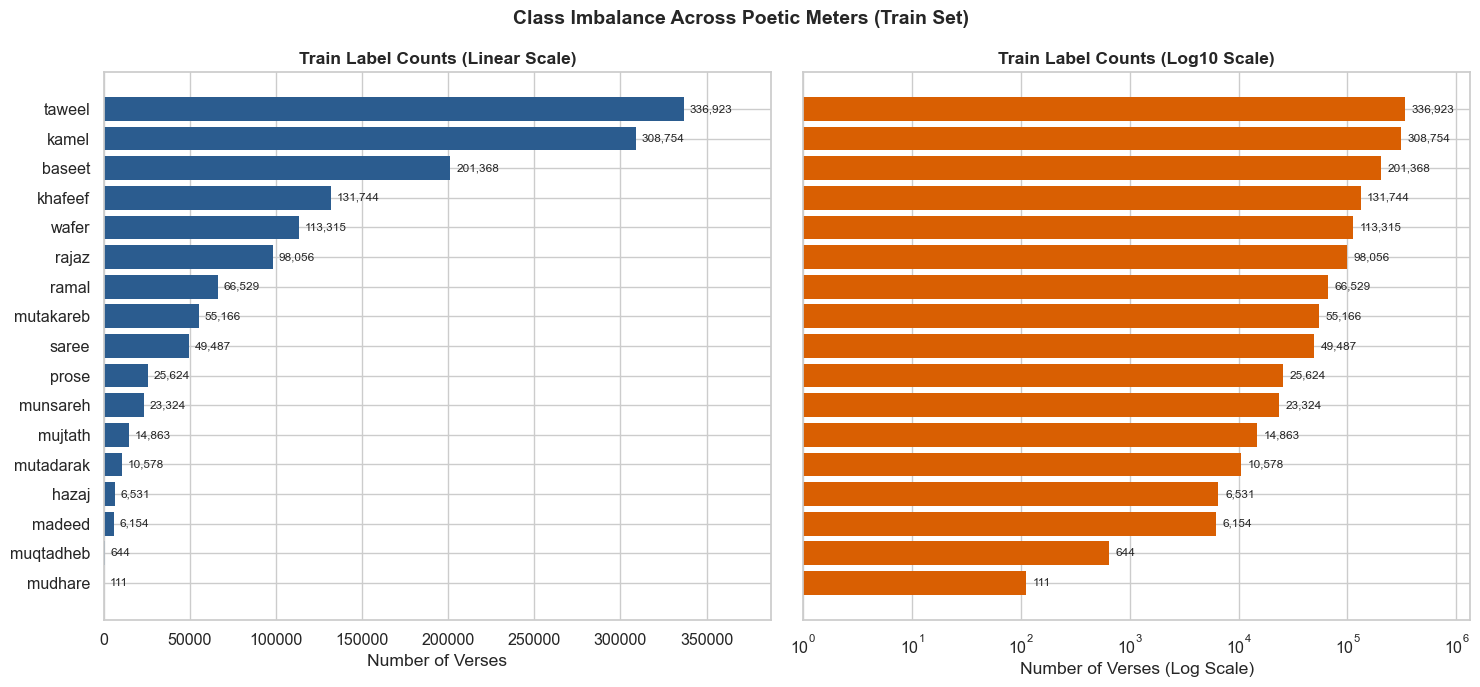

In [43]:
# CHART 1: Label Counts (Linear Scale vs. Log Scale)
counts = train_df["label_disp"].value_counts().reindex(label_order)

fig, axes = plt.subplots(1, 2, figsize=(15, 7), sharey=True)

# Left: Linear scale
axes[0].barh(counts.index[::-1], counts.values[::-1], color="#2b5c8f", edgecolor="none")
axes[0].set_title("Train Label Counts (Linear Scale)", fontweight="bold")
axes[0].set_xlabel("Number of Verses")
for idx, val in enumerate(counts.values[::-1]):
    axes[0].text(val + counts.max() * 0.01, idx, f"{val:,}", va="center", fontsize=8.5)
axes[0].set_xlim(0, counts.max() * 1.15)

# Right: Log scale
axes[1].barh(counts.index[::-1], counts.values[::-1], color="#d95f02", edgecolor="none")
axes[1].set_xscale("log")
axes[1].set_title("Train Label Counts (Log10 Scale)", fontweight="bold")
axes[1].set_xlabel("Number of Verses (Log Scale)")
for idx, val in enumerate(counts.values[::-1]):
    axes[1].text(val * 1.15, idx, f"{val:,}", va="center", fontsize=8.5)
axes[1].set_xlim(1, counts.max() * 4)

fig.suptitle("Class Imbalance Across Poetic Meters (Train Set)", fontsize=14, fontweight="bold", y=0.98)
plt.tight_layout()
plt.savefig("eda_charts/1_label_counts.png", dpi=300, bbox_inches="tight")
plt.show()

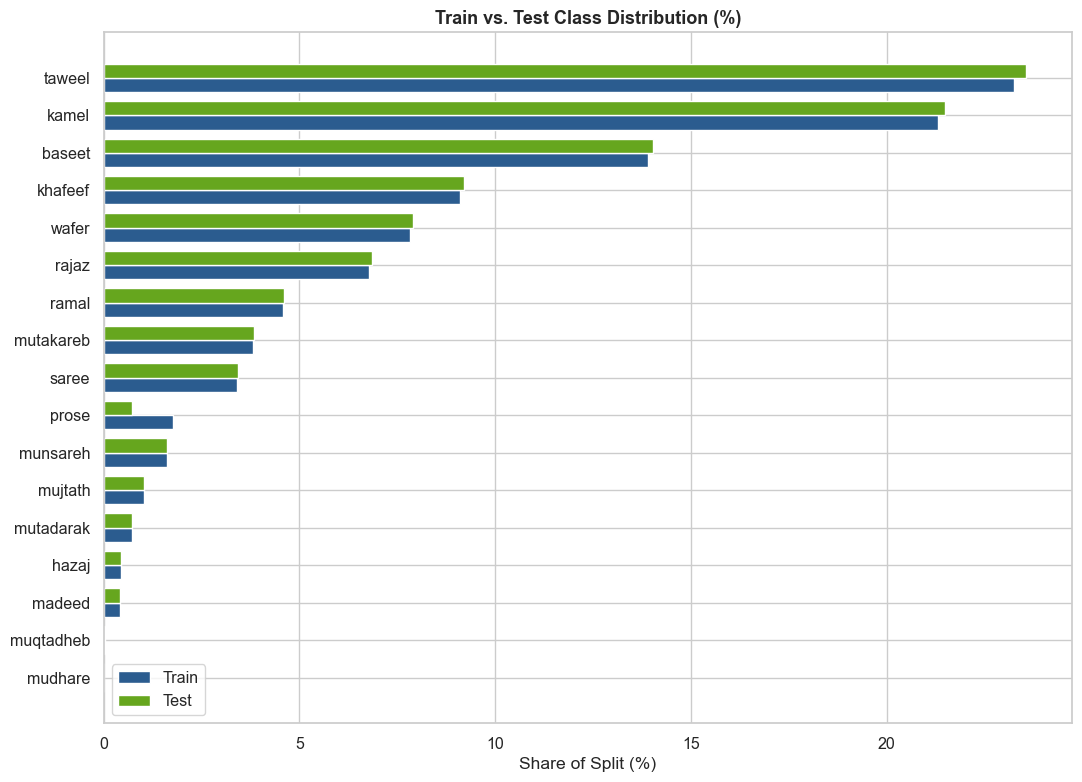

In [44]:
# CHART 2: Train vs. Test Label Percentages Side by Side
train_pct = (train_df["label_disp"].value_counts(normalize=True) * 100).reindex(label_order, fill_value=0)
test_pct = (test_df["label_disp"].value_counts(normalize=True) * 100).reindex(label_order, fill_value=0)

comp_df = pd.DataFrame({
    "Label": label_order,
    "Train (%)": train_pct.values,
    "Test (%)": test_pct.values
})

y = np.arange(len(comp_df))
height = 0.38

fig, ax = plt.subplots(figsize=(11, 8))
ax.barh(y - height/2, comp_df["Train (%)"][::-1], height, label="Train", color="#2b5c8f")
ax.barh(y + height/2, comp_df["Test (%)"][::-1], height, label="Test", color="#66a61e")

ax.set_yticks(y)
ax.set_yticklabels(comp_df["Label"][::-1])
ax.set_xlabel("Share of Split (%)")
ax.set_title("Train vs. Test Class Distribution (%)", fontsize=13, fontweight="bold")
ax.legend(frameon=True)

plt.tight_layout()
plt.savefig("eda_charts/2_train_vs_test_percentages.png", dpi=300, bbox_inches="tight")
plt.show()

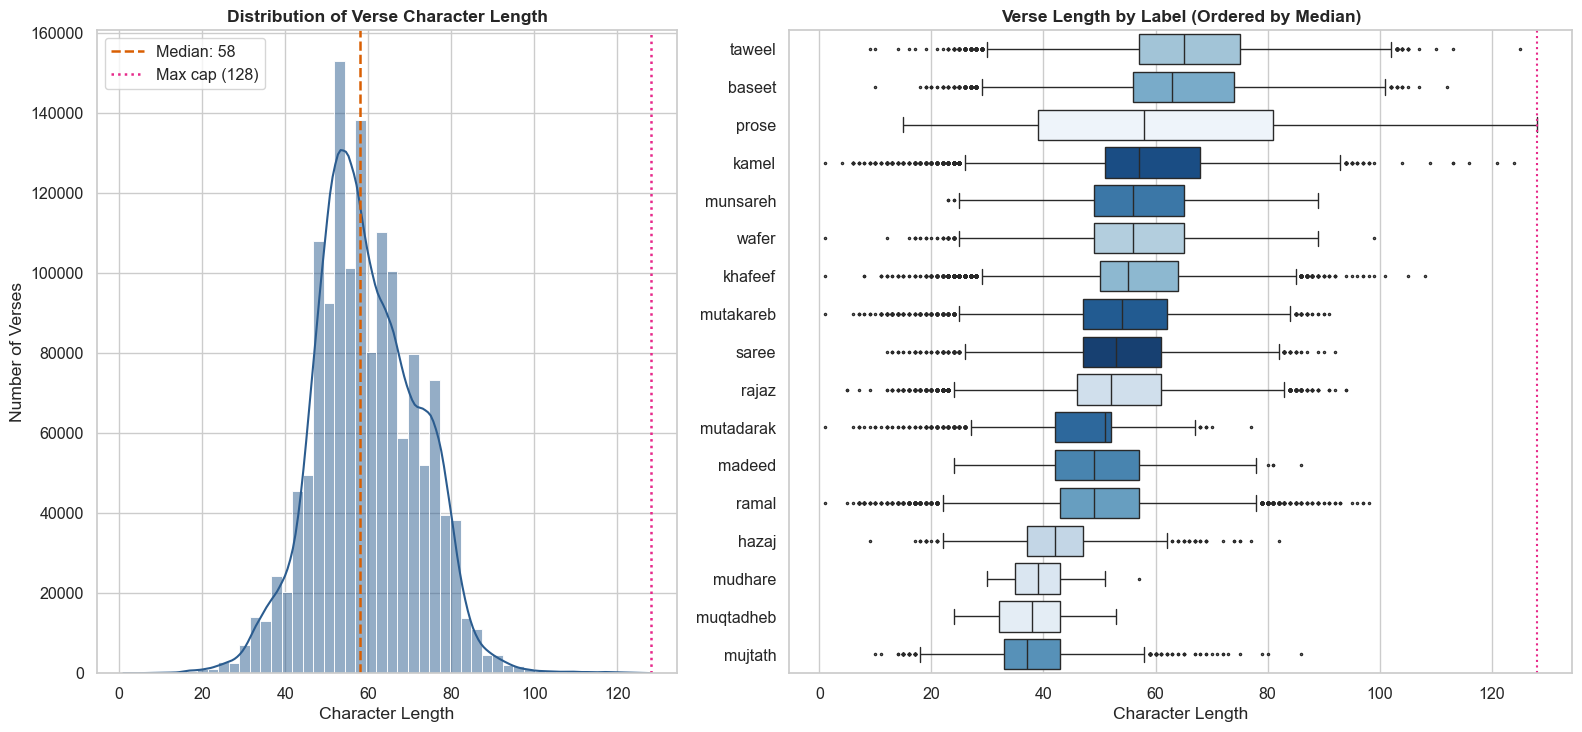

In [45]:
# CHART 3: Verse Length Histogram & Boxplot by Label
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5), gridspec_kw={"width_ratios": [1, 1.35]})

# Left: Histogram of character length
sns.histplot(train_df["char_len"], bins=50, kde=True, color="#2b5c8f", ax=axes[0])
median_len = train_df["char_len"].median()
axes[0].axvline(median_len, color="#d95f02", linestyle="--", linewidth=1.8, label=f"Median: {median_len:.0f}")
axes[0].axvline(128, color="#e7298a", linestyle=":", linewidth=1.8, label="Max cap (128)")
axes[0].set_title("Distribution of Verse Character Length", fontweight="bold")
axes[0].set_xlabel("Character Length")
axes[0].set_ylabel("Number of Verses")
axes[0].legend()

# Right: Boxplot by label (sorted by median length)
median_order = (
    train_df.groupby("label_disp")["char_len"]
    .median()
    .sort_values(ascending=False)
    .index
)
sns.boxplot(
    data=train_df,
    x="char_len",
    y="label_disp",
    hue="label_disp",      # <-- ties the palette to the y-axis labels
    order=median_order,
    palette="Blues_r",
    legend=False,          # <-- prevents seaborn from drawing an unnecessary legend
    fliersize=1.5,
    ax=axes[1]
)
axes[1].axvline(128, color="#e7298a", linestyle=":", linewidth=1.5)
axes[1].set_title("Verse Length by Label (Ordered by Median)", fontweight="bold")
axes[1].set_xlabel("Character Length")
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig("eda_charts/3_verse_length_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

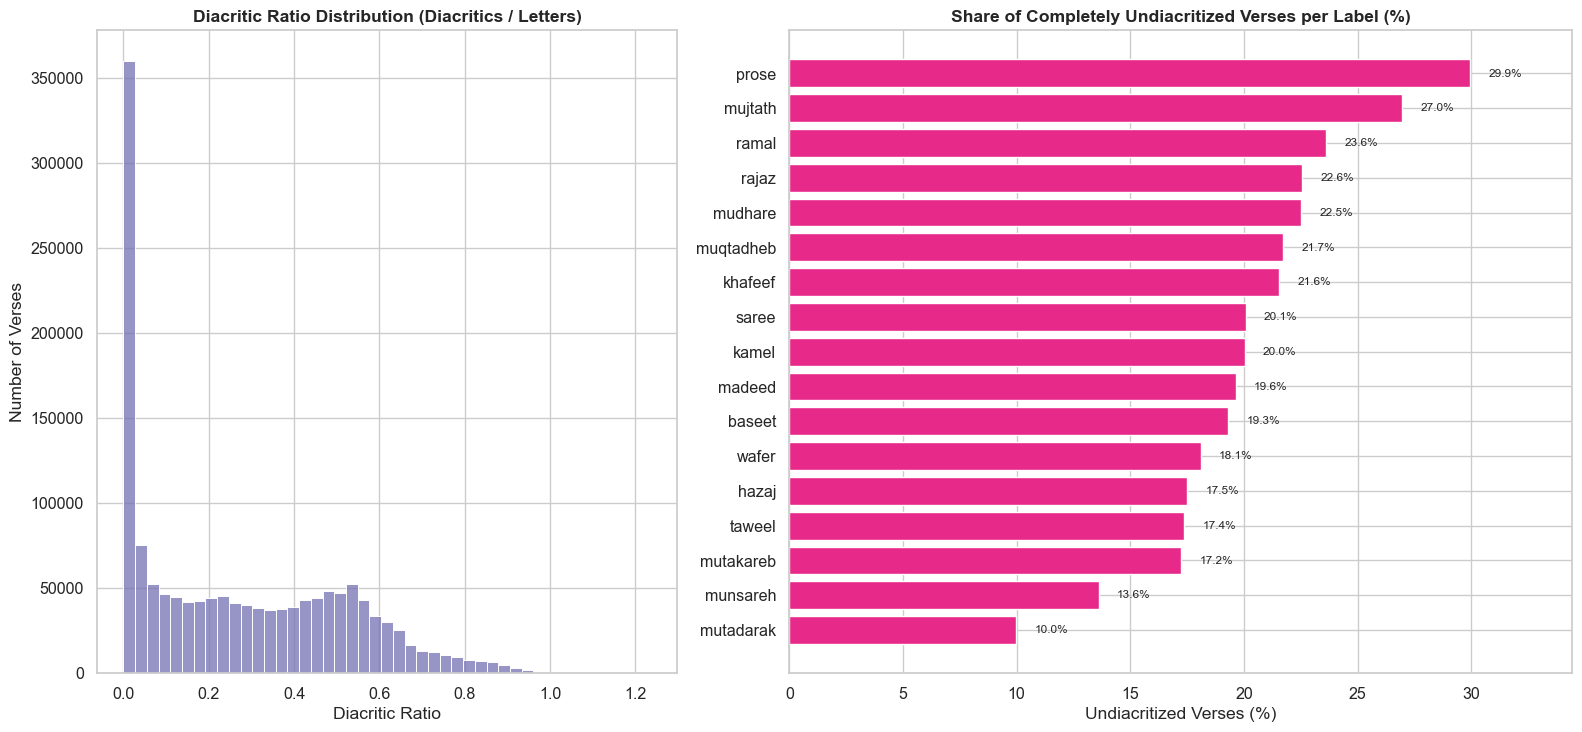

In [46]:
# CHART 4: Diacritic Ratio Histogram & Share of Undiacritized Verses per Label
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5), gridspec_kw={"width_ratios": [1, 1.35]})

# Left: Diacritic ratio distribution
sns.histplot(train_df["diac_ratio"].dropna(), bins=45, color="#7570b3", ax=axes[0])
axes[0].set_title("Diacritic Ratio Distribution (Diacritics / Letters)", fontweight="bold")
axes[0].set_xlabel("Diacritic Ratio")
axes[0].set_ylabel("Number of Verses")

# Right: % of completely undiacritized verses (diac_ratio == 0) per label
undiac_share = (
    train_df.assign(undiac=train_df["diac_ratio"] == 0)
    .groupby("label_disp")["undiac"]
    .mean()
    .mul(100)
    .sort_values(ascending=True)
)

bars = axes[1].barh(undiac_share.index, undiac_share.values, color="#e7298a")
axes[1].set_title("Share of Completely Undiacritized Verses per Label (%)", fontweight="bold")
axes[1].set_xlabel("Undiacritized Verses (%)")
axes[1].set_xlim(0, max(undiac_share.max() * 1.15, 10))

for bar in bars:
    w = bar.get_width()
    axes[1].text(w + 0.8, bar.get_y() + bar.get_height()/2, f"{w:.1f}%", va="center", fontsize=8.5)

plt.tight_layout()
plt.savefig("eda_charts/4_diacritics_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

**Findings per chart**
1. **Label counts (linear and log scale):** the imbalance is clear. The log scale is needed to see the smallest classes next to `taweel`.
2. **Train vs test percentages:** the two files match for every class except **`prose`** (about 1.8% in train and 0.7% in test).
3. **Verse length in characters (histogram and boxplot by label):** the distribution is centered near 58 characters with no verse above 128. Meters differ in median length, and `prose` has by far the widest spread. These charts count the حركات; with letters only (section 7), the meter order stays the same and the spread inside each meter is much smaller.
4. **Diacritic ratio (histogram and share of unmarked verses per label):** a spike at 0, a plateau, and a second hump near 0.5. `prose` has the highest share of unmarked verses in the bar chart, but also the heaviest marking among the marked ones.

## 10. Preprocessing and feature engineering

**`text`**
| Problem | Action | Why |
|---|---|---|
| Empty and half-verse rows (6,316 train, 1,537 test) | Drop | half the rhythm; label not reliable |
| Exact duplicates in test (1,146) | Drop, keeping the first | each بيت counts once |
| Conflicting-label verses (about 509 in train, 23 in test) | Drop all copies *(to confirm)* | no way to know the right بحر; the loss is about 0.035% |
| 8,935 verses in both files | Remove from train, leave test | no leakage |
| Nulls, تطويل, digits, Latin | No action | none found |

**`label`**: encode the 17 strings as integers and save the mapping; keep `prose` as the "not موزون" class *(to confirm)*; use class weights and macro-F1; avoid naive oversampling of `mudhare`; take a **stratified** validation split from train after deduplication; **shuffle** train.

**Features**
| Group | Examples | Why | Needs التشكيل? |
|---|---|---|---|
| Length | letters (`n_letters`, without حركات) and words in the بيت and in each شطر, difference between the أشطر | meters differ in length, and letter count is far more consistent inside a meter than character count (std 3 to 5 letters vs 10 to 11 characters) | no |
| التشكيل | ratio to letters; counts of فتحة، ضمة، كسرة، سكون، شدّة، تنوين; none/partial/full flag | separates `prose`; shows data quality | yes |
| Syllable pattern | sequence of المقاطع القصيرة والطويلة, its n-grams, syllable count | the strongest feature: a بحر is a pattern of long and short syllables | yes, fully |
| Text representation | character n-gram TF-IDF, character embeddings, a pretrained Arabic model | keeps letter and mark sequences | better with them |


## 11. ydata_profiling report
an automatic full report on the columns, as a cross-check of the manual analysis.
profiled a **random sample of 100,000 train rows** (`random_state=42`, not `head()`, because train is sorted by label), with the columns `text`, `label`, `char_len`, `diac_ratio`. Output: `ashaar_meter_profile.html`.

In [47]:
from ydata_profiling import ProfileReport

sample_df = train_df[["text", "label", "char_len", "diac_ratio"]].sample(100_000, random_state=42)

profile = ProfileReport(sample_df, title="Ashaar_meter - train sample")
profile.to_file("ashaar_meter_profile.html")

C:\Users\User\AppData\Local\Temp\ipykernel_18064\1559850180.py:1: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


%|                                                                                            | 0/4 [00:00<?, ?it/s]
100%|████████████████████████████████████████████████████████████████████████████████████| 4/4 [00:07<00:00,  1.89s/it]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

## 12. Model Recommendations

| Tier | Model | Input | Why | Its role | Effort |
| :--- | :--- | :--- | :--- | :--- | :--- |
| Baseline | TF-IDF on **character n-grams** (1 to 5) + Logistic Regression or linear SVM (use `SGDClassifier` for 1.4M rows), with class weights | The مشكول text, letters and marks as characters | Fast, and shows how much is learnable from characters alone | The reference number. It shows how much a simple model gets from letters and marks alone. | Low. It runs fast, even on a lot of data. |
| **Main model** | **Character-level BiGRU or BiLSTM** (or a 1D CNN), with an embedding layer | The text with `#` kept | A بحر is a pattern of letters and حركات in order, so a sequence model that reads characters keeps the rhythm | The model you actually propose. It reads the verse letter by letter and learns the rhythm pattern. | Medium. It needs training, ideally on a GPU. |
| Optional | Fine-tune a pretrained Arabic transformer, or a character-level one such as CANINE | Same | Stronger, but heavy. **Check that its tokenizer keeps التشكيل**, or it throws away the signal | An extension you try if time allows, to see if a bigger model does better. | High. It's heavy to fine-tune, and it may lose the تشكيل. |
| Best bet | The BiGRU **plus the syllable-pattern features** from step 6 | Text + features | Combines learning with the prosody rules | The expected best result. It combines learning with the prosody rules. | Medium to high. It needs the تشكيل to be full enough to build the pattern. |
